## 1.基于InMemoryStore
### 按照namespace前缀搜索

In [1]:
from langgraph.store.memory import InMemoryStore

store = InMemoryStore()
namespace1 = ("users","alice","memories")
key1="preferences"
value1 = {
    "course": "计算机组成原理",
    "sports": "跑步",
    "food": "紫光园奶皮子酸奶"
}

namespace2 = ("users", "Bob", "memories")
key2 = 'preferences'
value2 = {
    "course": "数字电路与模拟电路",
    "sports": "跑步",
    "food": "奶皮子糖葫芦"
}

namespace3 = ("users", "Black", "memories")
key3 = 'preferences'
value3 = {
    "course": "数字电路与模拟电路",
    "sports": "羽毛球",
    "food": "紫光园奶皮子酸奶"
}

store.put(namespace1, key1,value1)
store.put(namespace2, key2,value2)
store.put(namespace3, key3,value3)

for item in store.search(("users",)):
    print(item)

Item(namespace=['users', 'alice', 'memories'], key='preferences', value={'course': '计算机组成原理', 'sports': '跑步', 'food': '紫光园奶皮子酸奶'}, created_at='2026-10-29T02:16:30.557515+00:00', updated_at='2026-10-29T02:16:30.557518+00:00', score=None)
Item(namespace=['users', 'Bob', 'memories'], key='preferences', value={'course': '数字电路与模拟电路', 'sports': '跑步', 'food': '奶皮子糖葫芦'}, created_at='2026-10-29T02:16:30.557549+00:00', updated_at='2026-10-29T02:16:30.557550+00:00', score=None)
Item(namespace=['users', 'Black', 'memories'], key='preferences', value={'course': '数字电路与模拟电路', 'sports': '羽毛球', 'food': '紫光园奶皮子酸奶'}, created_at='2026-10-29T02:16:30.557573+00:00', updated_at='2026-10-29T02:16:30.557574+00:00', score=None)


In [2]:
for item in store.search(("users", "Black", "memories")):
    print(item)

Item(namespace=['users', 'Black', 'memories'], key='preferences', value={'course': '数字电路与模拟电路', 'sports': '羽毛球', 'food': '紫光园奶皮子酸奶'}, created_at='2026-10-29T02:16:30.557573+00:00', updated_at='2026-10-29T02:16:30.557574+00:00', score=None)


In [3]:
for item in store.search(("users", "alice")):
    print(item)

Item(namespace=['users', 'alice', 'memories'], key='preferences', value={'course': '计算机组成原理', 'sports': '跑步', 'food': '紫光园奶皮子酸奶'}, created_at='2026-10-29T02:16:30.557515+00:00', updated_at='2026-10-29T02:16:30.557518+00:00', score=None)


### 按照filter过滤

In [4]:
for item in store.search(("users",),filter={"food":"紫光园奶皮子酸奶"}):
    print(item)

Item(namespace=['users', 'alice', 'memories'], key='preferences', value={'course': '计算机组成原理', 'sports': '跑步', 'food': '紫光园奶皮子酸奶'}, created_at='2026-10-29T02:16:30.557515+00:00', updated_at='2026-10-29T02:16:30.557518+00:00', score=None)
Item(namespace=['users', 'Black', 'memories'], key='preferences', value={'course': '数字电路与模拟电路', 'sports': '羽毛球', 'food': '紫光园奶皮子酸奶'}, created_at='2026-10-29T02:16:30.557573+00:00', updated_at='2026-10-29T02:16:30.557574+00:00', score=None)


In [5]:
for item in store.search(("users",),filter={"sports":"羽毛球"}):
    print(item)

Item(namespace=['users', 'Black', 'memories'], key='preferences', value={'course': '数字电路与模拟电路', 'sports': '羽毛球', 'food': '紫光园奶皮子酸奶'}, created_at='2026-10-29T02:16:30.557573+00:00', updated_at='2026-10-29T02:16:30.557574+00:00', score=None)


### 按照语义搜索

举例1：自定义嵌入函数（将一段文本转换为一个多维向量的函数）
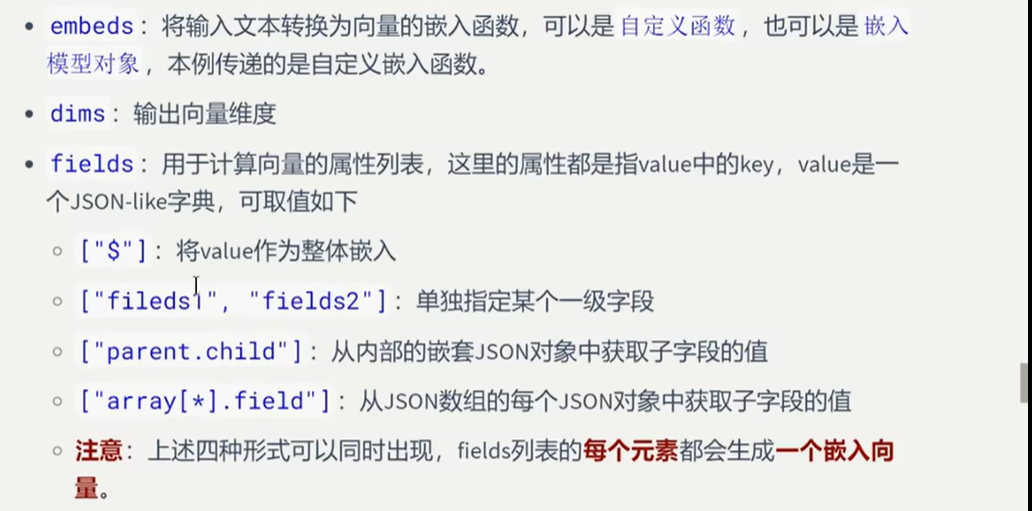

In [1]:
from langgraph.store.memory import InMemoryStore

# 自定义嵌入函数
def embed(text: list[str]) -> list[list[float]]:
    return [[1.0] * 6 for _ in range(len(text))]

index_config = {
    "embed": embed, # 使用嵌入函数或嵌入模型赋值
    "dims": 6,
    "fields": ["$", "course"]
}
store = InMemoryStore(
    index = index_config
)

namespace1 = ("users", "Alice", "memories")
key1 = 'preferences'
value1 = {
    "course": "计算机组成原理",
    "sports": "跑步",
    "food": "紫光园奶皮子酸奶"
}

namespace2 = ("users", "Bob", "memories")
key2 = 'preferences'
value2 = {
    "course": "数字电路与模拟电路",
    "sports": "跑步",
    "food": "奶皮子糖葫芦"
}

namespace3 = ("users", "Black", "memories")
key3 = 'preferences'
value3 = {
    "course": "数字电路与模拟电路",
    "sports": "羽毛球",
    "food": "紫光园奶皮子酸奶"
}

store.put(namespace1, key1, value1)
store.put(namespace2, key2, value2)
store.put(namespace3, key3, value3)

In [2]:
# 查看嵌入向量
from pprint import pprint
pprint(store._vectors)

defaultdict(<function InMemoryStore.__init__.<locals>.<lambda> at 0x000001F653AD32E0>,
            {('users', 'Alice', 'memories'): defaultdict(<class 'dict'>,
                                                         {'preferences': {'$': [1.0,
                                                                                1.0,
                                                                                1.0,
                                                                                1.0,
                                                                                1.0,
                                                                                1.0],
                                                                          'course': [1.0,
                                                                                     1.0,
                                                                                     1.0,
                                                           

In [3]:
from pprint import pprint
pprint(store._vectors[('users', 'Alice', 'memories')]['preferences']['$'])

[1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


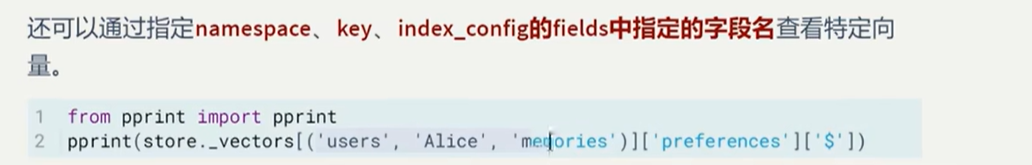

举例2：使用嵌入模型

In [4]:
from langgraph.store.memory import InMemoryStore
from dotenv import load_dotenv
from langchain.embeddings import init_embeddings

import os
load_dotenv(override=True)

# 本地嵌入模型的初始化,不需要api_key 和base_url
embedding_model = init_embeddings(
	model="ollama:embeddinggemma-2:latest",
)

index_config = {
    "embed": embedding_model,
    "dims": 3072,
    "fields": ["$"]
}
store = InMemoryStore(
    index = index_config
)

namespace1 = ("users", "Alice", "memories")
key1 = 'preferences'
value1 = {
    "course": "计算机组成原理",
    "sports": "跑步",
    "food": "紫光园奶皮子酸奶"
}

namespace2 = ("users", "Bob", "memories")
key2 = 'preferences'
value2 = {
    "course": "数字电路与模拟电路",
    "sports": "跑步",
    "food": "奶皮子糖葫芦"
}

namespace3 = ("users", "Black", "memories")
key3 = 'preferences'
value3 = {
    "course": "数字电路与模拟电路",
    "sports": "羽毛球",
    "food": "紫光园奶皮子酸奶"
}

store.put(namespace1, key1, value1)
store.put(namespace2, key2, value2)
store.put(namespace3, key3, value3)



In [5]:
for item in store.search(("users", ), query="数电模电"):
    print(item)

Item(namespace=['users', 'Black', 'memories'], key='preferences', value={'course': '数字电路与模拟电路', 'sports': '羽毛球', 'food': '紫光园奶皮子酸奶'}, created_at='2026-11-02T01:04:19.970641+00:00', updated_at='2026-11-02T01:04:19.970645+00:00', score=0.8060068288445519)
Item(namespace=['users', 'Bob', 'memories'], key='preferences', value={'course': '数字电路与模拟电路', 'sports': '跑步', 'food': '奶皮子糖葫芦'}, created_at='2026-11-02T01:04:19.837582+00:00', updated_at='2026-11-02T01:04:19.837586+00:00', score=0.7920389944550469)
Item(namespace=['users', 'Alice', 'memories'], key='preferences', value={'course': '计算机组成原理', 'sports': '跑步', 'food': '紫光园奶皮子酸奶'}, created_at='2026-11-02T01:04:19.742544+00:00', updated_at='2026-11-02T01:04:19.742548+00:00', score=0.752632429361972)


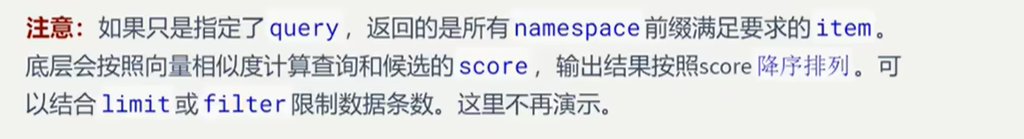